# Mini project 3: The project

## Objective
We want to determine at which point the function 
$$
y=xe^{x^2},
$$

crosses the unit circle in the $x$-positive, $y$-positive quadrant using fixed-point simple iteration.

You should already have rewritten the problem 
in the form of a fixed-point problem, i.e. 
$$
x=g(x)
$$
that is suitable for iteration.

As well as the Guided Example for miniproject 3, the Guided Examples from miniprojects 1 and 2 can also be used as a guide for completing the tasks.

## The tasks
1. Plot the two curves to determine a starting point for iteration. Save the graph in a PDF file. 
*Hint: use `np.linspace` to generate an array with the x values. `np.exp` and `np.sqrt` returns an array with the exp and square root of the elements of the array given in input.* 
2. Write a function `myfun` that calculates $g(x)$. The function takes `x` and returns the value of the function at `x`.
3. Write a function `SimpleIter` that performs the simple iteration to find the abscissa of the intersection point. The function takes the initial guess `x0` and the tolerance `tol`. It returns the list of approximations generated by the simple iteration. To perform the iteration, use a `while` loop that performs
   $$
   x_n = g(x_{n-1}),
   $$
   while the absolute difference between the approximation of two successive approximation is larger than the tolerance.
5. Execute the `SimpleIter` using the starting approximation you estimated from the plot and setting the tolerance to `1e-15`. 
6. Consider the last value in the list of approximations generated by `SimpleIter` being the reference value. Generate the list of absolute errors, by taking the absolute value of the difference between the approximation and the reference value. 
*Hint: note that if you subtract a number from a list, it returns a list in which the number is subtracted from each element, similarly taking the absolute value of a list returns the list of the absolute values of the elements).
7. Plot the error at iteration $n$ against the error at iteration $n - 1$. Save the graph into a PDF file.  

# Python code


0.5808750357617375
0.8139927474055283


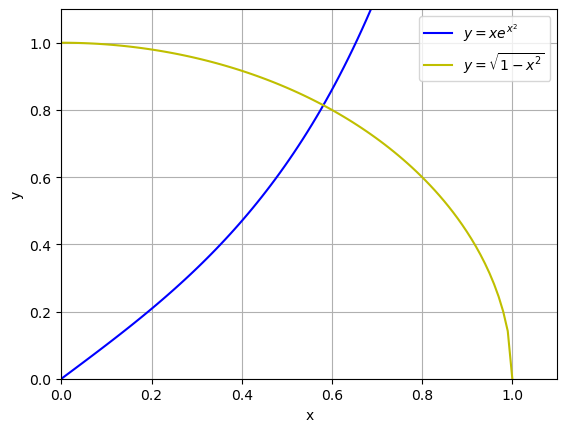

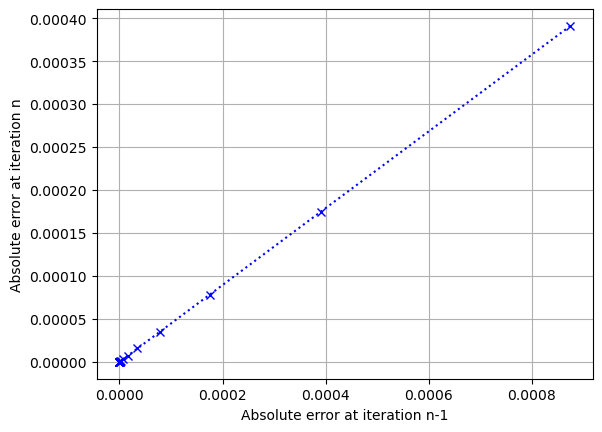

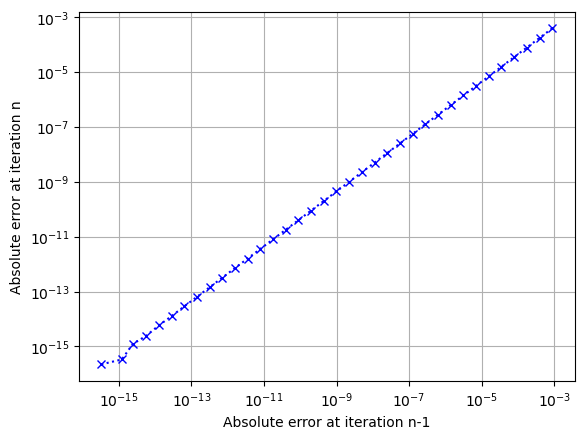

In [18]:
import numpy as np
import math
import matplotlib.pyplot as plt

#Setting variables
x = np.linspace(0,1,100)
y1 = x * np.exp(x**2)
y2 = np.sqrt(1-x**2)

#Plotting graph
plt.figure()
plt.plot(x,y1, color='b', label=r'$y = x e^{x^2}$')
plt.plot(x,y2, color='y', label=r'$y = \sqrt{1 - x^2}$')

#Setting limits
plt.axis([0,1.1,0,1.1])

#Lables and grid
plt.ylabel('y')
plt.xlabel('x')
plt.grid(True)
plt.legend()
plt.savefig('graph1')

#Function to calculate x_n = g(x_{n-1})
def myfun(x):
    return (1 / np.sqrt(1 + np.exp(2 * x**2)))

#Function to calculate x_n while abs difference between x_n and x_{n-1} is greater than a given tolerance
def SimpleIter(x0,tol):

    #Setting variables
    approx = [x0]
    diff = tol + 1
    n = 0

    #Getting x_n while abs differnece between x_n and x_{n-1} is greater than a given tolerance
    while diff > tol:
        approx.append(myfun(approx[n]))

        diff = abs(approx[n] - approx[n-1])
        n += 1
        
    return approx

#Setting variables
x0 = 0.58
tol = 1e-15
approx = SimpleIter(x0,tol)
refVal = approx[-1]
absErr = abs(approx - refVal)

#Printing intersection point
print(refVal)
print(np.sqrt(1-refVal**2))

#Plotting graph
plt.figure()
plt.plot(absErr[0:-2],absErr[1:-1], 'b:x')

#Labels and grid
plt.ylabel('Absolute error at iteration n')
plt.xlabel('Absolute error at iteration n-1')
plt.grid(True)
plt.savefig('graph2')

#Plotting graph
plt.figure()
plt.loglog(absErr[0:-2],absErr[1:-1], 'b:x')

#Labels and grid
plt.ylabel('Absolute error at iteration n')
plt.xlabel('Absolute error at iteration n-1')
plt.grid(True)
plt.savefig('graph3')